# Immuno Compass · Notebook 04: Features and the "no peeking" test system (Day 4)

**Goal:** (1) fix the final list of clues (features) with a reason for each, (2) build the preprocessing recipe
that turns them into numbers, and (3) create the **train/test folds that every model will share**.

**Finish line:** `data/processed/folds.csv` saved; preprocessing tested on every fold; a demonstration of why a
random split would cheat.

> 🧒 *Simple version:* we decide which clues the detectives get, translate the clues into a language computers
> understand, and set up a fair exam where the test questions are always about medicines the student has **never seen**.

**Shared code:** the feature lists, preprocessing and scoring live in `src/immuno.py`, so notebooks 05–13 use *exactly*
the same recipe. That's what makes the model comparison fair.

In [1]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, KFold
np.random.seed(42)

df = im.load_cohorts(ROOT)
print(df.shape, "| drugs:", df[im.DRUG].nunique())

(1754, 38) | drugs: 137


## 1 · The final feature list, with a reason for each

| Feature | Type | Why it's in | Expected direction (from biology / Day 3) |
|---|---|---|---|
| `species` | category | How "foreign" the protein looks to the immune system | bacterial > chimeric > humanized ≥ human |
| `modality` | category | Kind of drug (antibody, ADC, immunotoxin…) | immunotoxins high |
| `backbone` | category | Antibody skeleton (IgG1/IgG2/IgG4) | unclear |
| `expression` | category | Cells used to make it (affects sugars on the protein) | unclear |
| `route` | category | IV vs under the skin vs eye | SC often thought higher |
| `indication` | category | Disease area; patients' immune state differs | autoimmune > cancer |
| `co_immunosuppressant` | 0/1 | Immune-calming co-medication | lower ADA once disease is accounted for |
| `co_any_drug` | 0/1 | Any combination therapy | unclear |
| `log_dose_mgkg` (+ missing flag) | number | Dose; very high doses may induce tolerance | non-linear |
| `dose_type` | category | How the dose was written; also says if the dose is weight-based | none |
| `start_year` (+ missing flag) | number | Newer ADA assays are more sensitive | later → higher |
| `log_followup_days` (+ missing flag) | number | Longer follow-up = more chances to detect ADA | longer → higher |
| `blinding`, `randomized`, `comparator` | category | Study design / reporting differences | none expected |
| `arm_mentions_placebo` | 0/1 | Arm partly on placebo | lower |
| `biosimilar` | 0/1 | Copies of existing drugs (often tested with sensitive assays) | unclear |

**Dropped on purpose:**
* `light_chain` and `conjugate`: almost duplicates of `modality` (correlation 0.85 / 0.83).
* `dose_missing`: identical to the missing-flag the imputer creates.
* `design` (prospective/retrospective): 99 % one value.
* `source`, `audited`: they describe the database entry, not the drug, patient or trial.
* **Drug name / drug ID:** using it would let models memorise drugs; we want them to generalise to new drugs.
* **Sequence features:** added and tested separately on Days 11–12.

In [3]:
print("categorical:", im.CAT_FEATURES)
print("numeric    :", im.NUM_FEATURES)
print("flags      :", im.FLAG_FEATURES)
print("\nmissing values per feature:")
print(df[im.ALL_FEATURES].isna().sum()[lambda s: s > 0].to_string())
print("\nlevels per categorical feature:")
for c in im.CAT_FEATURES:
    print(f"  {c:12s} {df[c].nunique()} → {sorted(df[c].unique())}")

categorical: ['route', 'indication', 'blinding', 'randomized', 'comparator', 'dose_type', 'modality', 'species', 'backbone', 'expression']
numeric    : ['log_dose_mgkg', 'start_year', 'log_followup_days']
flags      : ['co_immunosuppressant', 'co_any_drug', 'arm_mentions_placebo', 'biosimilar']

missing values per feature:
log_dose_mgkg        154
start_year            14
log_followup_days     46

levels per categorical feature:
  route        4 → ['Intravenous', 'Ophthalmic', 'Other', 'Subcutaneous']
  indication   7 → ['Cancer and neoplasms', 'Cardiovascular', 'Healthy Volunteer', 'Inflammation and autoimmunity', 'Musculoskeletal', 'Neurological', 'Other']
  blinding     5 → ['Double', 'Open Label', 'Other', 'Triple', 'Unknown']
  randomized   3 → ['Not Randomized', 'Randomized', 'Unknown']
  comparator   4 → ['Active controls', 'Parallel Assignment', 'Placebo/Sham', 'Unknown']
  dose_type    4 → ['Unknown', 'flat', 'per kg', 'per m2']
  modality     4 → ['Antibody-drug conjugate', '

## 2 · Preprocessing recipe (fit on training data only)

* **Categories → one-hot:** "route = Subcutaneous" becomes a 0/1 column. The first level of each feature is dropped
  as the *reference* (its effect is absorbed by the intercept).
* **Numbers → median-imputed + "was missing" flag → standardised** (mean 0, SD 1), so the GLM and Bayesian coefficients
  are comparable and the Bayesian prior "Normal(0, 1)" makes sense.
* XGBoost doesn't need scaling; it uses the same recipe with `scale=False`.

⚠️ **Pitfall:** if we computed the median or the scaling using *all* data, the test fold would leak into training.
That's why the recipe is fit inside each fold.

In [4]:
pre = im.make_preprocessor(scale=True).fit(df)
X_all = pd.DataFrame(pre.transform(df), columns=pre.get_feature_names_out())
print("final design matrix:", X_all.shape, "(cohorts × numeric columns)")
print(list(X_all.columns))

final design matrix: (1754, 45) (cohorts × numeric columns)
['route_Ophthalmic', 'route_Other', 'route_Subcutaneous', 'indication_Cardiovascular', 'indication_Healthy Volunteer', 'indication_Inflammation and autoimmunity', 'indication_Musculoskeletal', 'indication_Neurological', 'indication_Other', 'blinding_Open Label', 'blinding_Other', 'blinding_Triple', 'blinding_Unknown', 'randomized_Randomized', 'randomized_Unknown', 'comparator_Parallel Assignment', 'comparator_Placebo/Sham', 'comparator_Unknown', 'dose_type_flat', 'dose_type_per kg', 'dose_type_per m2', 'modality_Immunotoxin', 'modality_Monoclonal antibody', 'modality_Other', 'species_Chimeric', 'species_Human', 'species_Humanized', 'species_Other', 'backbone_Human IgG2', 'backbone_Human IgG4', 'backbone_Not applicable', 'backbone_Other', 'expression_Murine myeloma cells', 'expression_Other', 'expression_Undetermined', 'log_dose_mgkg', 'start_year', 'log_followup_days', 'missingindicator_log_dose_mgkg', 'missingindicator_start_

### Check for redundant columns
Pairs with |correlation| > 0.8 make GLM coefficients unstable. We removed the worst offenders above; let's confirm.

In [5]:
corr = X_all.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high = upper.stack()[lambda s: s > 0.7].sort_values(ascending=False)
print("pairs with |r| > 0.7:" if len(high) else "no pairs with |r| > 0.7 ✔")
display(high.round(2).to_frame("abs_corr"))

pairs with |r| > 0.7:


,,abs_corr
species_Human,species_Humanized,0.78
dose_type_flat,dose_type_per kg,0.77
randomized_Unknown,comparator_Unknown,0.73
route_Ophthalmic,expression_Other,0.71


Remaining high pairs are **two levels of the same category** (e.g. species Human vs Humanized: if it isn't one it is
usually the other). That's normal for one-hot encoding and not a problem.

## 3 · The folds: grouped by drug (the main exam) and random (the cheating exam)

**Grouped 5-fold CV:** every drug is in exactly one test fold. When a fold is the test set, **none** of its drugs
were seen in training. This mimics the real question: *"what ADA rate should we expect for a new drug?"*

**Random 5-fold CV:** cohorts are shuffled without regard to drug, so the same drug sits in train and test.
We keep it **only** to show how much it inflates scores.

In [6]:
folds = pd.DataFrame({"cohort_id": df["cohort_id"], im.DRUG: df[im.DRUG]})
folds["fold_grouped"] = -1
for k, (_, test_idx) in enumerate(GroupKFold(n_splits=5).split(df, groups=df[im.DRUG])):
    folds.loc[test_idx, "fold_grouped"] = k
folds["fold_random"] = -1
for k, (_, test_idx) in enumerate(KFold(n_splits=5, shuffle=True, random_state=42).split(df)):
    folds.loc[test_idx, "fold_random"] = k
assert (folds[["fold_grouped", "fold_random"]] >= 0).all().all()

# The key guarantee: no drug appears in more than one grouped fold.
assert folds.groupby(im.DRUG)["fold_grouped"].nunique().max() == 1, "a drug leaked across folds!"
leak = folds.groupby(im.DRUG)["fold_random"].nunique()
print(f"grouped folds: 0 drugs shared between folds ✔")
print(f"random folds : {(leak > 1).sum()} of {len(leak)} drugs appear in more than one fold (that's the leak)")

folds.to_csv(ROOT / "data" / "processed" / "folds.csv", index=False)
print("saved data/processed/folds.csv")

grouped folds: 0 drugs shared between folds ✔
random folds : 114 of 137 drugs appear in more than one fold (that's the leak)
saved data/processed/folds.csv


In [7]:
d = df.join(folds[["fold_grouped", "fold_random"]])
fold_stats = d.groupby("fold_grouped").agg(cohorts=("n", "size"), drugs=(im.DRUG, "nunique"), patients=("n", "sum"),
                                           ada_pos=("y", "sum"))
fold_stats["pooled_ADA"] = fold_stats["ada_pos"] / fold_stats["patients"]
display(fold_stats.style.format({"pooled_ADA": "{:.1%}", "patients": "{:,.0f}"}))
print("Folds differ in pooled ADA because each holds different drugs. That's real drug-to-drug variation,")
print("and it's why we will report the spread across folds, not just the average.")

,cohorts,drugs,patients,ada_pos,pooled_ADA
fold_grouped,,,,,
0,351,27,"38,203",3173,8.3%
1,351,27,"46,204",7624,16.5%
2,351,28,"46,124",4220,9.1%
3,351,28,"41,892",3290,7.9%
4,350,27,"38,595",8834,22.9%


Folds differ in pooled ADA because each holds different drugs. That's real drug-to-drug variation,
and it's why we will report the spread across folds, not just the average.


## 4 · Test the recipe on every fold

In [8]:
for k in range(5):
    tr, te = d[d["fold_grouped"] != k], d[d["fold_grouped"] == k]
    pre_k = im.make_preprocessor(scale=True).fit(tr)
    Xtr, Xte = pre_k.transform(tr), pre_k.transform(te)
    assert not np.isnan(Xtr).any() and not np.isnan(Xte).any()
    assert set(tr[im.DRUG]).isdisjoint(te[im.DRUG])
    print(f"fold {k}: train {Xtr.shape}, test {Xte.shape}, no missing values ✔, no shared drugs ✔")

fold 0: train (1403, 45), test (351, 45), no missing values ✔, no shared drugs ✔
fold 1: train (1403, 44), test (351, 44), no missing values ✔, no shared drugs ✔
fold 2: train (1403, 45), test (351, 45), no missing values ✔, no shared drugs ✔


fold 3: train (1403, 45), test (351, 45), no missing values ✔, no shared drugs ✔


fold 4: train (1404, 45), test (350, 45), no missing values ✔, no shared drugs ✔


/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


ℹ️ The *"Found unknown categories"* warning is expected. A rare level (species "Other") belongs to a single drug, so
when that drug sits in the test fold, training has never seen the level. It is encoded as all zeros (= the reference level).
That's exactly what would happen for a genuinely new kind of drug.

## 5 · Two baselines, and why a random split cheats

Before any real model, we set the bar with two "dumb" predictors:

* **Naive baseline:** always predict the training data's pooled ADA %. Every real model **must beat this**.
* **Drug memoriser:** if the drug was seen in training, predict that drug's training ADA %; otherwise fall back to the naive guess.
  It knows nothing about biology; it just remembers drugs.

**Scores** (same for every model from now on):
* **wMAE:** average gap between predicted and observed ADA %, weighting big cohorts more (lower = better)
* **wRMSE:** like wMAE but punishes big misses more (lower = better)
* **loglik:** how probable the observed counts are under the predicted rate (higher = better; it rewards good probabilities)

In [9]:
def naive(train, test):
    return np.full(len(test), train["y"].sum() / train["n"].sum())

def drug_memoriser(train, test):
    overall = train["y"].sum() / train["n"].sum()
    per_drug = train.groupby(im.DRUG)[["y", "n"]].sum()
    rate = (per_drug["y"] / per_drug["n"])
    return test[im.DRUG].map(rate).fillna(overall).values

results = []
for split in ["fold_random", "fold_grouped"]:
    for name, fn in [("naive baseline", naive), ("drug memoriser", drug_memoriser)]:
        per_fold, _ = im.cross_validate(d, split, fn)
        m, s = per_fold.drop(columns="fold").mean(), per_fold.drop(columns="fold").std()
        results.append({"split": "random (cheating)" if split == "fold_random" else "grouped by drug (honest)",
                        "model": name, **{f"{c}": m[c] for c in m.index}, **{f"{c}_sd": s[c] for c in s.index}})
res = pd.DataFrame(results)
display(res.style.format({c: "{:.3f}" for c in res.columns if c not in ("split", "model")}).hide(axis="index"))

split,model,wMAE,wRMSE,loglik,wMAE_sd,wRMSE_sd,loglik_sd
random (cheating),naive baseline,0.133,0.190,-17.349,0.016,0.031,4.969
random (cheating),drug memoriser,0.075,0.129,-9.024,0.019,0.029,2.321
grouped by drug (honest),naive baseline,0.137,0.189,-18.057,0.038,0.060,7.983
grouped by drug (honest),drug memoriser,0.137,0.189,-18.057,0.038,0.060,7.983


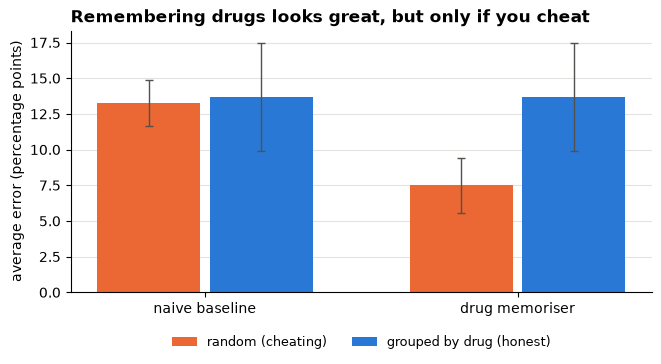

In [10]:
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight"})
fig, ax = plt.subplots(figsize=(7.5, 3.4))
labels = ["naive baseline", "drug memoriser"]
x = np.arange(len(labels)); w = 0.36
for i, (split, color) in enumerate([("random (cheating)", ORANGE), ("grouped by drug (honest)", BLUE)]):
    r = res[res["split"] == split].set_index("model").loc[labels]
    ax.bar(x + (i - 0.5) * w, r["wMAE"] * 100, w - 0.03, yerr=r["wMAE_sd"] * 100, color=color, label=split,
           error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
ax.set_xticks(x, labels); ax.set_ylabel("average error (percentage points)")
ax.set_title("Remembering drugs looks great, but only if you cheat")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2); ax.grid(axis="x", visible=False)
fig.savefig(ROOT / "figures" / "leakage_demo.png"); plt.show()

## 6 · Day 4 findings (write-up)

* **Features:** 17 raw clues (10 categories, 3 numbers, 4 yes/no flags) → **45 numeric columns** after one-hot encoding. Light chain, conjugate, duplicate dose flag, design, source and audit status were dropped with stated reasons. The drug's name/ID is deliberately **not** a feature.
* **Preprocessing** (median imputation + missing flags + standardisation) is fit **inside each training fold** and lives in `src/immuno.py`, so every model uses the identical recipe.
* **Folds:** 5 grouped folds of ~350 cohorts / ~27 drugs each, with **zero drugs shared between folds**. Fold pooled ADA ranges from 8 % to 23 %, because different drugs land in different folds. Expect model scores to vary across folds too.
* **Leakage demonstration:** a "drug memoriser" that only remembers each drug's past ADA rate cuts the error from **13.3 → 7.5 percentage points** under a random split. Under the honest grouped split it is **no better than the naive baseline (13.7 points)**, because it has never seen the test drugs. A random split would make any model look far better than it really is for a *new* drug.
* **The bar to beat:** naive baseline under grouped CV: **wMAE ≈ 0.137, wRMSE ≈ 0.189, loglik ≈ −18.1** (fold SD 0.038 / 0.060 / 8.0). Every model from Day 5 on must beat this to be useful.